# FreshHarvest Freshness Inspection using CNN

This notebook builds a reproducible image-classification prototype for warehouse produce inspection. It predicts one of 16 combined labels, covering eight produce types in fresh and spoiled conditions.

## 1. Business framing

Manual inspection can vary with lighting, fatigue, and operator judgment. The model provides a consistent first-pass decision and confidence score. Low-confidence cases should be routed to a human inspector rather than automatically accepted or rejected.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.datasets import ImageFolder

from train_model import build_dataloaders, predict_image, train

DATA_DIR = Path('data/FRUIT-16K')
ARTIFACTS_DIR = Path('artifacts')
assert DATA_DIR.exists(), 'Extract the supplied archive under data/ first.'

## 2. Dataset audit and class balance

In [2]:
dataset = ImageFolder(DATA_DIR)
counts = {name: dataset.targets.count(index) for index, name in enumerate(dataset.classes)}
print(f'Total images: {len(dataset):,}')
print(f'Number of classes: {len(dataset.classes)}')
counts

Total images: 16,000
Number of classes: 16


{'F_Banana': 1000,
 'F_Lemon': 1000,
 'F_Lulo': 1000,
 'F_Mango': 1000,
 'F_Orange': 1000,
 'F_Strawberry': 1000,
 'F_Tamarillo': 1000,
 'F_Tomato': 1000,
 'S_Banana': 1000,
 'S_Lemon': 1000,
 'S_Lulo': 1000,
 'S_Mango': 1000,
 'S_Orange': 1000,
 'S_Strawberry': 1000,
 'S_Tamarillo': 1000,
 'S_Tomato': 1000}

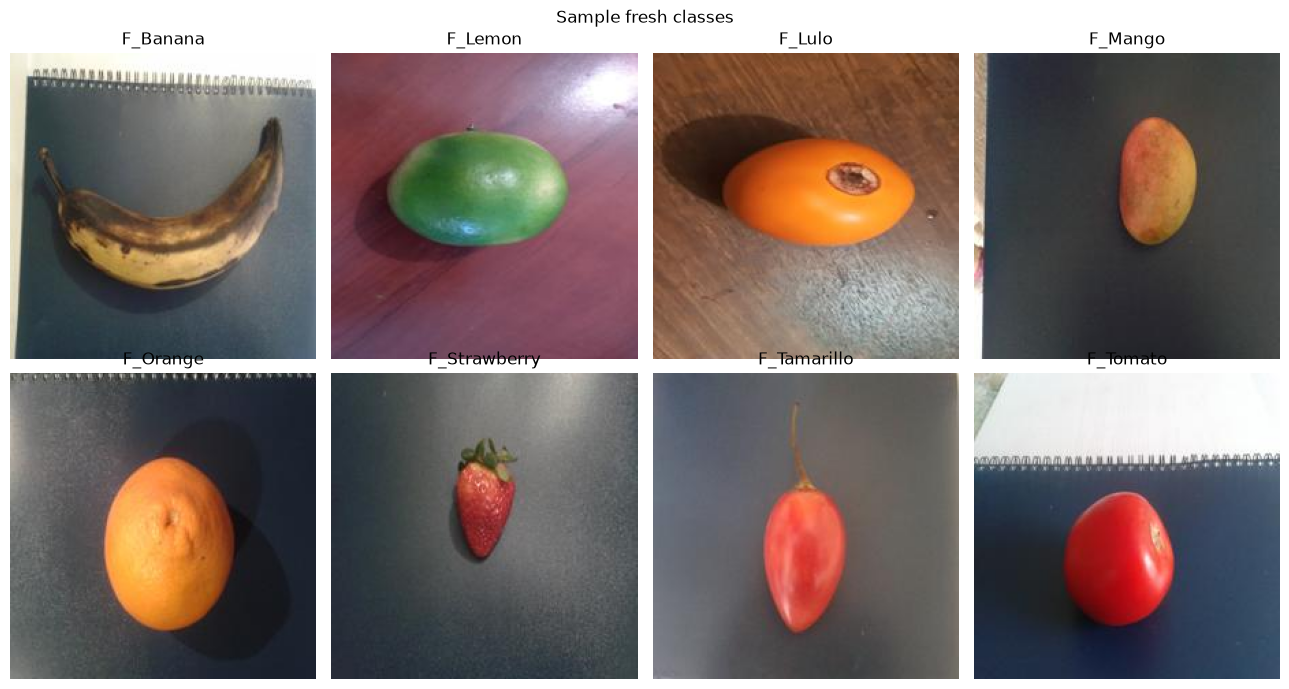

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for axis, class_name in zip(axes.flat, dataset.classes[:8]):
    index = dataset.class_to_idx[class_name]
    path = next(path for path, label in dataset.samples if label == index)
    axis.imshow(Image.open(path).convert('RGB'))
    axis.set_title(class_name)
    axis.axis('off')
plt.suptitle('Sample fresh classes')
plt.tight_layout()

## 3. Modeling approach

The baseline CNN is trained from scratch and contains four convolutional stages with batch normalization, ReLU activation, and max pooling. Following the assignment requirement, this first model uses no transfer learning, data augmentation, dropout, weight decay, or label smoothing. The split is stratified and deterministic: 70% training, 15% validation, and 15% final testing.

In [4]:
classes, datasets, loaders = build_dataloaders(DATA_DIR)
{name: len(split) for name, split in datasets.items()}

{'train': 11200, 'val': 2400, 'test': 2400}

## 4. Train and evaluate

In [5]:
metrics = train(
    DATA_DIR, ARTIFACTS_DIR, epochs=8, batch_size=64, epoch_candidates=(3, 5, 8)
)
{
    'best_validation_accuracy': metrics['best_validation_accuracy'],
    'test_16_class_accuracy': metrics['test_class_accuracy'],
    'test_fresh_spoiled_accuracy': metrics['test_freshness_accuracy'],
}

Device: cuda | Classes: 16 | Split sizes: 11200/2400/2400
Epoch 01: train loss=1.1349, acc=0.6616 | val loss=0.7014, acc=0.7696
Epoch 02: train loss=0.4141, acc=0.8835 | val loss=0.2491, acc=0.9308
Epoch 03: train loss=0.2200, acc=0.9402 | val loss=0.4325, acc=0.8525
Epoch 04: train loss=0.1312, acc=0.9663 | val loss=0.1712, acc=0.9458
Epoch 05: train loss=0.1192, acc=0.9658 | val loss=0.0721, acc=0.9771
Epoch 06: train loss=0.0894, acc=0.9751 | val loss=0.2766, acc=0.9096
Epoch 07: train loss=0.0772, acc=0.9774 | val loss=0.0999, acc=0.9700
Epoch 08: train loss=0.0650, acc=0.9821 | val loss=0.0642, acc=0.9792
Best validation accuracy: 0.9792
Test 16-class accuracy: 0.9796
Test fresh/spoiled accuracy: 0.9946


{'best_validation_accuracy': 0.9791666666666666,
 'test_16_class_accuracy': 0.9795833333333334,
 'test_fresh_spoiled_accuracy': 0.9945833333333334}

In [6]:
# Compare the requested epoch experiments using validation data only.
[(row['epoch'], round(row['val_accuracy'] * 100, 2)) for row in metrics['epoch_experiments']]

[(3, 85.25), (5, 97.71), (8, 97.92)]

## 5. Single-image prediction

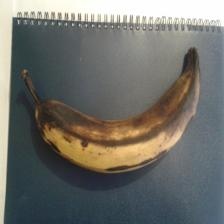

{'produce': 'Banana',
 'freshness': 'Spoiled',
 'class_label': 'S_Banana',
 'confidence': 0.9987996816635132}

In [7]:
sample_path = Path(dataset.samples[0][0])
result = predict_image(sample_path, ARTIFACTS_DIR / 'best_model.pt')
display(Image.open(sample_path).convert('RGB'))
result

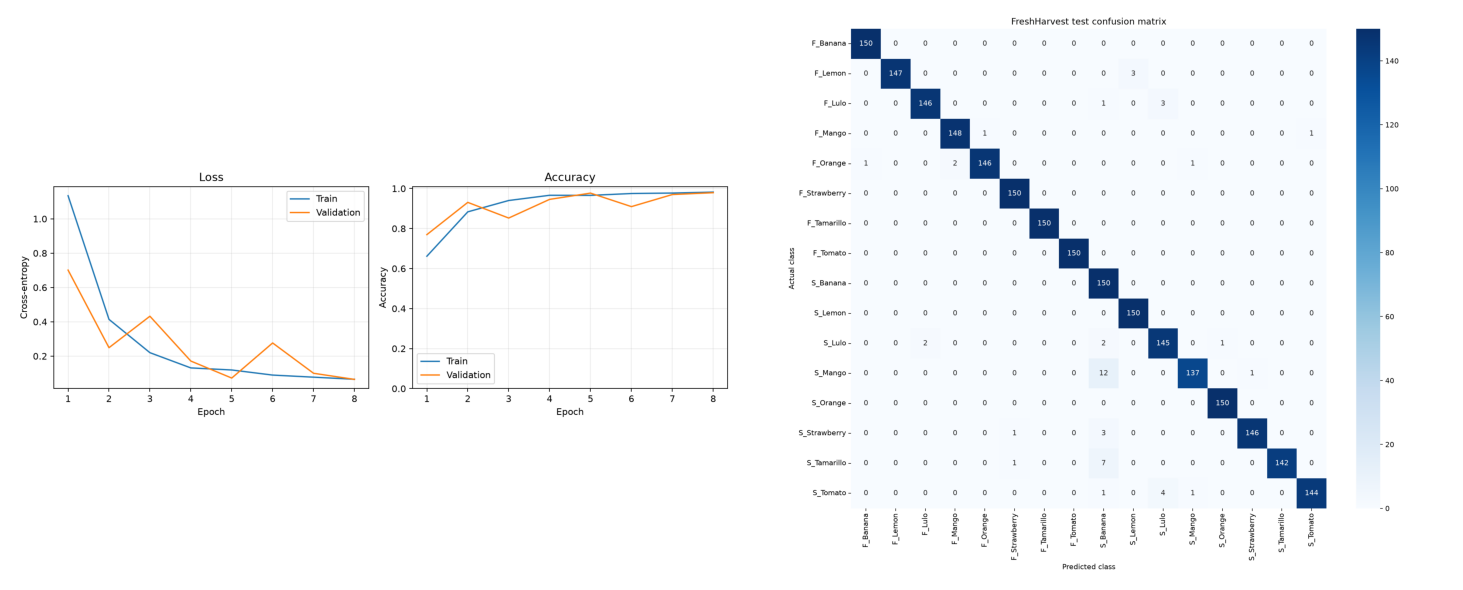

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].imshow(plt.imread(ARTIFACTS_DIR / 'training_history.png'))
axes[0].axis('off')
axes[1].imshow(plt.imread(ARTIFACTS_DIR / 'confusion_matrix.png'))
axes[1].axis('off')
plt.tight_layout()

## 6. Business interpretation and deployment guardrails

- The 16-class score measures exact produce-and-condition recognition.
- The binary freshness score measures the operational fresh-versus-spoiled decision.
- Before conveyor deployment, test on images from the real warehouse cameras and lighting.
- Use a confidence threshold and send uncertain images to a manual review queue.
- Monitor class-specific recall, especially for spoiled products, because missed spoilage is costlier than an extra manual check.
- Watch for camera drift, seasonal appearance changes, and new packaging or backgrounds.